<a href="https://colab.research.google.com/github/sadmansakib18/CVPR-TASK-1-MID/blob/main/CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
import gdown, zipfile, os

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cpu


In [25]:
file_id = '1T7AiZdRBtwxRV7_Inim82szlPyNfRHs5'
gdown.download(id=file_id, output='data.zip', quiet=False)

with zipfile.ZipFile('data.zip', 'r') as z:
    z.extractall('data')

# Check the folder names inside 'data'
for root, dirs, files in os.walk('data'):
    print(root, dirs)

Downloading...
From (original): https://drive.google.com/uc?id=1T7AiZdRBtwxRV7_Inim82szlPyNfRHs5
From (redirected): https://drive.google.com/uc?id=1T7AiZdRBtwxRV7_Inim82szlPyNfRHs5&confirm=t&uuid=72904b2d-6629-4173-ae27-df130f5988d1
To: /content/data.zip
100%|██████████| 434M/434M [00:07<00:00, 57.5MB/s]


data ['Multi-Source Agricultural Image Dataset for Robust', 'extracted_dataset']
data/Multi-Source Agricultural Image Dataset for Robust []
data/extracted_dataset ['Multi-Source Agricultural Image Dataset for Robust Classification and Semantic\xa0Segmentation']
data/extracted_dataset/Multi-Source Agricultural Image Dataset for Robust Classification and Semantic Segmentation ['Flowers', 'Fruits', 'Vegetables', 'Crops or Grains']
data/extracted_dataset/Multi-Source Agricultural Image Dataset for Robust Classification and Semantic Segmentation/Flowers ['Chinese Ixora', 'Sacred Tree', 'Chrysanthemum', 'Rangoon Creeper', 'Zinnia', 'Scarlet Sage', 'Yesterday-Today-Tomorrow', 'Rose Landora', 'Hibiscus', 'Cockscomb', 'Shoeblack', 'Genda', 'Garden Rose White', 'Rose Veterans Honor', 'Peace Rose', 'Garden Rose', 'Ixora Coccinea', 'Marigold', 'Damask Rose', 'Dahlia', 'Yellow Elder', 'China Rose', 'Rose Kristall', 'Silver flower', 'Brunfelsia']
data/extracted_dataset/Multi-Source Agricultural Imag

In [26]:
import zipfile
import os

base_dir = 'data/Multi-Source Agricultural Image Dataset for Robust'
inner_zip_path = None

# Programmatically look for the zip file to avoid syntax/encoding issues with hardcoded paths
if os.path.exists(base_dir):
    for file in os.listdir(base_dir):
        if file.endswith('.zip'):
            inner_zip_path = os.path.join(base_dir, file)
            break

if inner_zip_path and os.path.exists(inner_zip_path):
    print(f"Extracting: {inner_zip_path}")
    with zipfile.ZipFile(inner_zip_path, 'r') as z:
        z.extractall('data/extracted_dataset')
else:
    print("Inner zip file not found.")

# Find the subfolder containing actual class directories
# Since there might be another nested folder inside 'extracted_dataset'
class_root_dir = 'data/extracted_dataset'
for root, dirs, files in os.walk('data/extracted_dataset'):
    # If we find a directory that contains subdirectories, and we are not in the top root
    # we will inspect it to find where the classes are stored.
    if len(dirs) > 0:
        print(f"Found directories in {root}: {dirs[:5]}")

transform = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.ToTensor()
])

# Typically, we can point to the folder containing subfolders
# Adjust 'dataset_root' based on output prints if the structure is nested deeper
dataset_root = 'data/extracted_dataset'
full_ds = datasets.ImageFolder(root=dataset_root, transform=transform)

train_size = int(0.8 * len(full_ds))
test_size = len(full_ds) - train_size
train_ds, test_ds = random_split(full_ds, [train_size, test_size])

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True)
test_dl = DataLoader(test_ds, batch_size=64, shuffle=True)

print("Classes:", full_ds.classes)
print("Train:", len(train_ds))
print("Test:", len(test_ds))

Extracting: data/Multi-Source Agricultural Image Dataset for Robust/Multi-Source Agricultural Image Dataset for Robust Classification and Semantic Segmentation.zip
Found directories in data/extracted_dataset: ['Multi-Source Agricultural Image Dataset for Robust Classification and Semantic\xa0Segmentation']
Found directories in data/extracted_dataset/Multi-Source Agricultural Image Dataset for Robust Classification and Semantic Segmentation: ['Flowers', 'Fruits', 'Vegetables', 'Crops or Grains']
Found directories in data/extracted_dataset/Multi-Source Agricultural Image Dataset for Robust Classification and Semantic Segmentation/Flowers: ['Chinese Ixora', 'Sacred Tree', 'Chrysanthemum', 'Rangoon Creeper', 'Zinnia']
Found directories in data/extracted_dataset/Multi-Source Agricultural Image Dataset for Robust Classification and Semantic Segmentation/Fruits: ['Grapes', 'Jamun', 'Watermelon', 'Apple', 'Pineapple']
Found directories in data/extracted_dataset/Multi-Source Agricultural Image 

In [27]:
#CNN Build
class CustomCNN(nn.Module):
  def __init__(self):
    super().__init__()
    #Convolutional Block
    self.conv1 = nn.Conv2d(3, 8, kernel_size=3, padding=1)
    self.conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1)
    self.pool = nn.MaxPool2d(2,2)
    #ANN
    #how to calculate 28*28 -> 14*14 -> 7*7
    input_neurons = 16 * 7 * 7 #last layer feature * image size after max pool
    self.cls = nn.Linear(input_neurons, len(full_ds.classes))

  def forward(self, x):
    #image size 28
    x = self.conv1(x)
    x = F.relu(x)
    x = self.pool(x)
    #image size 28->14
    x = self.conv2(x)
    x = F.relu(x)
    x = self.pool(x)
    #image size 14->7
    x = torch.flatten(x, 1)
    x = self.cls(x)
    return x

model = CustomCNN().to(device)
print(model)

CustomCNN(
  (conv1): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (cls): Linear(in_features=784, out_features=1, bias=True)
)


In [28]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

for ep in range(5):
  model.train()
  correct, total = 0,0
  for img, label in train_dl:
    img,label = img.to(device), label.to(device)
    optimizer.zero_grad()
    output = model(img)
    loss = loss_fn(output, label)
    loss.backward() #gradient calculation
    optimizer.step() #weight update
    correct += torch.sum(torch.argmax(output, dim=1) == label).item()
    total += label.size(0)
  print(f"Ep {ep+1}: Train Acc {correct/total}")

Ep 1: Train Acc 1.0
Ep 2: Train Acc 1.0
Ep 3: Train Acc 1.0
Ep 4: Train Acc 1.0
Ep 5: Train Acc 1.0


In [29]:
img, label = test_ds[0]
x = img.unsqueeze(0).to(device)
model.eval()
with torch.no_grad():
  x = model.conv1(x)
  early = F.relu(x).cpu()[0] #early layer features 8
  x = model.pool(x)
  x = model.conv2(x)
  last = F.relu(x).cpu()[0] #last layer features 16

print(early.shape)
print(last.shape)

torch.Size([8, 28, 28])
torch.Size([16, 14, 14])


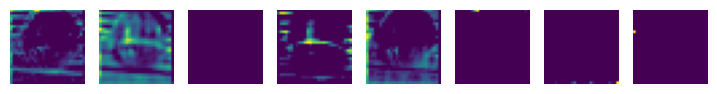

In [30]:
plt.figure(figsize=(9,2))
for i in range(8):
  plt.subplot(1,8,i+1)
  plt.imshow(early[i], cmap='viridis')
  plt.axis('off')

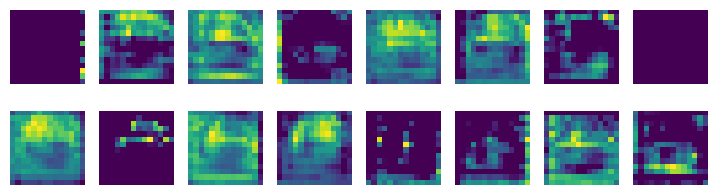

In [31]:
#2nd layer feature
plt.figure(figsize=(9,2.4))
for i in range(16):
  plt.subplot(2,8,i+1)
  plt.imshow(last[i], cmap='viridis')
  plt.axis('off')